# Model inputs

Which inputs should the linear regression and XGBoost use? The experiments in the app pointed to `downside_21d`, but they were judged on the 2018–2026 test scores, the same period we report. Here the choice is made on a validation period instead:

1. **Choose** on 2013–2017: train from 2003, refit at the start of each year, and score each candidate input set.
2. **Confirm** once on 2018–2026, the test period.
3. **Explain** why down days matter, and check that the coefficients are stable across refits.

In [1]:
# Pick up edits to src/volforecast without restarting the kernel
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression

from volforecast.data import load
from volforecast.evaluate import Split, score_table, training_rows
from volforecast.features import build_dataset, log_returns
from volforecast.models import ALL_FEATURES, fit_predict, make_xgboost

In [3]:
HORIZON = 21
TRAIN_START = "2003-01-01"
VALIDATION_YEARS = (2013, 2017)
BASE = ["rv_1d", "rv_5d", "rv_21d", "vix"]
CANDIDATES = {
    "default": BASE,
    "+ rv_63d": [*BASE, "rv_63d"],
    "+ downside_21d": [*BASE, "downside_21d"],
    "+ usdtry_21d": [*BASE, "usdtry_21d"],
    "all seven": list(ALL_FEATURES),
}
MODELS = {
    "linear regression": LinearRegression,
    "XGBoost": lambda: make_xgboost(n_estimators=300, max_depth=3, learning_rate=0.05),
}

xu100, vix, usdtry = load("xu100"), load("vix"), load("usdtry")
r = log_returns(xu100["Close"]).dropna()
data = build_dataset(r, vix["Close"], HORIZON, usdtry["Close"])
LAST_YEAR = data.index[-1].year

In [4]:
def yearly_forecasts(model_name: str, features: list[str], first: int, last: int) -> pd.Series:
    """Forecasts refitted at the start of each year on everything before it, as in the app."""
    pieces = []
    for year in range(first, last + 1):
        start, end = f"{year}-01-01", f"{year}-12-31"
        model = MODELS[model_name]()
        forecast = fit_predict(model, data, features, Split(TRAIN_START, start, HORIZON))
        pieces.append(forecast.loc[start:end])
    return pd.concat(pieces)


def compare(first: int, last: int, target: pd.Series) -> pd.DataFrame:
    """Scores of every model with every candidate input set, refitted yearly."""
    tables = {}
    for model_name in MODELS:
        forecasts = {
            name: yearly_forecasts(model_name, features, first, last)
            for name, features in CANDIDATES.items()
        }
        tables[model_name] = score_table(pd.DataFrame(forecasts), target)
    return pd.concat(tables)

## 1. Choose on 2013–2017

Scores of each candidate set over the validation years. Targets that reach into 2018 are left out, so the test period plays no part in the choice. Lower is better for MAE, RMSE and QLIKE.

In [5]:
first, last = VALIDATION_YEARS
end = f"{last}-12-31"
# Only targets that end before the test period, so no test returns leak into the choice
validation_target = data["target"].loc[:end].iloc[:-HORIZON]
compare(first, last, validation_target).round(3)

bias    MAE   RMSE  QLIKE
linear regression default         2.278  5.665  7.544  0.202
                  + rv_63d        1.926  5.392  7.328  0.194
                  + downside_21d  2.173  5.642  7.513  0.201
                  + usdtry_21d    2.019  5.617  7.583  0.210
                  all seven       1.760  5.459  7.459  0.204
XGBoost           default         2.654  5.966  7.866  0.219
                  + rv_63d        3.216  7.017  9.204  0.329
                  + downside_21d  2.627  6.016  7.889  0.220
                  + usdtry_21d    2.456  6.005  7.933  0.213
                  all seven       3.310  6.527  9.217  0.271

## 2. Confirm on 2018–2026

The same comparison on the test period, run once. The rows should match the app's runs with yearly refits.

In [6]:
compare(last + 1, LAST_YEAR, data["target"]).round(3)

bias    MAE    RMSE  QLIKE
linear regression default         0.105  6.828   9.124  0.241
                  + rv_63d       -0.010  6.729   9.074  0.246
                  + downside_21d  0.206  6.744   9.034  0.237
                  + usdtry_21d   -0.417  6.761   9.176  0.253
                  all seven      -0.433  6.674   9.164  0.262
XGBoost           default         0.174  7.214   9.632  0.268
                  + rv_63d        0.445  7.149   9.861  0.258
                  + downside_21d  0.200  7.332   9.802  0.273
                  + usdtry_21d    3.159  8.388  10.349  0.266
                  all seven       3.086  8.065  10.096  0.260

## 3. Why down days matter

Each date's last 21 days are put into one of five equal-sized groups, by how much of their variance came from down days. The bars show how much higher or lower the next 21 days' volatility was than the last 21 days', on average. If down days push volatility up (the leverage effect), the bars rise to the right.

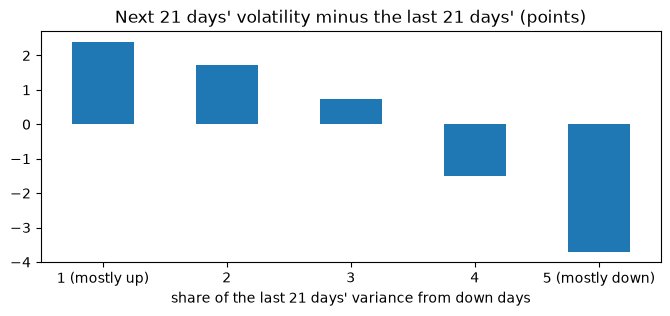

,mean,count
group,,
1 (mostly up),2.40,1187
2,1.73,1187
3,0.74,1187
4,-1.49,1187
5 (mostly down),-3.70,1187


In [7]:
recent = data.loc[TRAIN_START:]
columns = {
    "down share": (recent["downside_21d"] / recent["rv_21d"]) ** 2,
    "change": recent["target"] - recent["rv_21d"],
}
table = pd.DataFrame(columns).dropna()
labels = ["1 (mostly up)", "2", "3", "4", "5 (mostly down)"]
table["group"] = pd.qcut(table["down share"], 5, labels=labels)
summary = table.groupby("group", observed=True)["change"].agg(["mean", "count"])

title = "Next 21 days' volatility minus the last 21 days' (points)"
ax = summary["mean"].plot.bar(figsize=(8, 3), rot=0, title=title)
ax.set_xlabel("share of the last 21 days' variance from down days")
plt.show()
summary.round(2)

## 4. Are the coefficients stable?

The linear regression with `downside_21d`, refitted at the start of each year from 2008 on. A coefficient that keeps its sign and size across refits is a real effect; one that jumps around is noise.

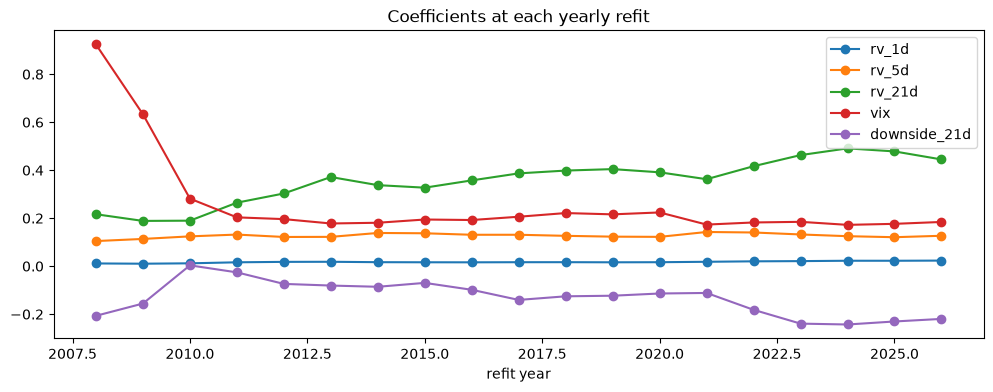

,rv_1d,rv_5d,rv_21d,vix,downside_21d
refit year,,,,,
2008,0.011,0.105,0.216,0.924,-0.207
2009,0.010,0.114,0.189,0.633,-0.156
2010,0.012,0.124,0.190,0.281,0.004
2011,0.016,0.132,0.265,0.203,-0.026
2012,0.018,0.122,0.303,0.196,-0.074
2013,0.018,0.122,0.372,0.178,-0.081
2014,0.017,0.138,0.338,0.181,-0.086
2015,0.016,0.137,0.327,0.195,-0.070
2016,0.016,0.131,0.358,0.192,-0.098


In [8]:
features = CANDIDATES["+ downside_21d"]
coefficients = {}
for year in range(2008, LAST_YEAR + 1):
    split = Split(TRAIN_START, f"{year}-01-01", HORIZON)
    train = training_rows(data[[*features, "target"]], split)
    model = LinearRegression().fit(train[features], train["target"])
    coefficients[year] = pd.Series(model.coef_, index=features)
by_year = pd.DataFrame(coefficients).T.rename_axis("refit year")

by_year.plot(figsize=(12, 4), marker="o", title="Coefficients at each yearly refit")
plt.show()
by_year.round(3)

## Findings

- **Validation picks `rv_63d`, not `downside_21d`.** On 2013–2017, adding quarterly volatility gives the linear regression its best MAE (5.39 vs 5.67 with the default inputs), RMSE (7.33 vs 7.54) and QLIKE (0.194 vs 0.202). `downside_21d` barely helps there (MAE 5.64), so its win in the app's experiments was partly luck.
- **On the test period, `rv_63d` only partly holds up.** The linear regression improves on MAE (6.73 vs 6.83) and RMSE (9.07 vs 9.12) but gets worse on QLIKE (0.246 vs 0.241).
- **XGBoost has its best MAE and RMSE with the default inputs** on 2013–2017. `rv_63d` hurts it most (RMSE 9.20 vs 7.87).
- **No leverage effect.** Months dominated by down days were followed by volatility 3.7 points lower on average, and months dominated by up days by 2.4 points higher. Part of that is mean reversion, because down-heavy months tend to be the most volatile, but the regression points the same way: with the other inputs held fixed, `downside_21d` gets a negative coefficient at every refit except 2010.
- **The down-day coefficient isn't stable.** It swings between about 0 and −0.24, while the `rv_21d` coefficient climbs from 0.19 to 0.49. The two inputs overlap and trade weight between them.